# ¿Se puede reconocer un partido investigado por apuestas mirando sus números?

En este EDA comparo los cuatro partidos de Malik Beasley descritos en la acusación federal con sus 79 encuentros de temporada regular de 2023-24. Mi objetivo no es decidir si un registro demuestra una manipulación, sino medir cuánto se distingue del rendimiento habitual del jugador.

## Fuentes y límites

Uso el registro oficial de partidos de NBA Stats, descargado mediante su API, y la acusación del Distrito Este de Nueva York. La acusación identifica cuatro fechas y describe apuestas sobre puntos y rebotes. Una acusación recoge alegaciones; a 28 de octubre de 2026, el abogado de Beasley ha anunciado un acuerdo para declararse culpable el 9 de diciembre, pero todavía no se conocen los cargos concretos incluidos.

No intento detectar fraude con estadísticas. Sin comunicaciones, movimientos de apuestas y otras pruebas, un partido raro no prueba una manipulación y un partido corriente no la descarta.

## 1. Preparación de los datos

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# cargo la copia local descargada de la api oficial
ruta_datos = Path('datos_malik_beasley_2023_24.csv')
datos = pd.read_csv(ruta_datos)
datos['FECHA'] = pd.to_datetime(datos['GAME_DATE'])
datos = datos.sort_values('FECHA').reset_index(drop=True)

print(f'Partidos: {len(datos)}')
datos[['GAME_DATE', 'MATCHUP', 'MIN', 'PTS', 'REB']].head()

Partidos: 79


,GAME_DATE,MATCHUP,MIN,PTS,REB
0,"Oct 26, 2023",MIL vs. PHI,31,5,4
1,"Oct 29, 2023",MIL vs. ATL,32,18,4
2,"Oct 30, 2023",MIL vs. MIA,32,5,3
3,"Nov 01, 2023",MIL @ TOR,25,20,2
4,"Nov 03, 2023",MIL vs. NYK,22,0,3


In [2]:
# anoto solo la información explícita necesaria de la acusación
casos = pd.DataFrame([
    {'FECHA': '2024-01-26', 'rival': 'Cleveland Cavaliers', 'objetivo': 'menos de 3,5 rebotes'},
    {'FECHA': '2024-02-27', 'rival': 'Charlotte Hornets', 'objetivo': 'menos de 12,5 puntos y más de 3,5 rebotes'},
    {'FECHA': '2024-03-10', 'rival': 'Los Angeles Clippers', 'objetivo': 'más de 3,5 rebotes'},
    {'FECHA': '2024-03-21', 'rival': 'Brooklyn Nets', 'objetivo': 'menos de 3,5 rebotes'},
])
casos['FECHA'] = pd.to_datetime(casos['FECHA'])
partidos = casos.merge(datos, on='FECHA', how='left', validate='one_to_one')
partidos[['FECHA', 'rival', 'objetivo', 'MIN', 'PTS', 'REB']]

,FECHA,rival,objetivo,MIN,PTS,REB
0,2024-01-26,Cleveland Cavaliers,"menos de 3,5 rebotes",27,3,3
1,2024-02-27,Charlotte Hornets,"menos de 12,5 puntos y más de 3,5 rebotes",26,6,4
2,2024-03-10,Los Angeles Clippers,"más de 3,5 rebotes",39,17,4
3,2024-03-21,Brooklyn Nets,"menos de 3,5 rebotes",31,16,6


## 2. Análisis: una línea que parte la temporada por la mitad

In [3]:
resumen = pd.Series({
    'partidos': len(datos),
    'media_puntos': datos['PTS'].mean(),
    'mediana_puntos': datos['PTS'].median(),
    'media_rebotes': datos['REB'].mean(),
    'mediana_rebotes': datos['REB'].median(),
    'partidos_3_o_menos_rebotes': (datos['REB'] <= 3).sum(),
    'partidos_4_o_mas_rebotes': (datos['REB'] >= 4).sum(),
})
resumen

partidos                      79.000000
media_puntos                  11.253165
mediana_puntos                10.000000
media_rebotes                  3.670886
mediana_rebotes                4.000000
partidos_3_o_menos_rebotes    39.000000
partidos_4_o_mas_rebotes      40.000000
dtype: float64

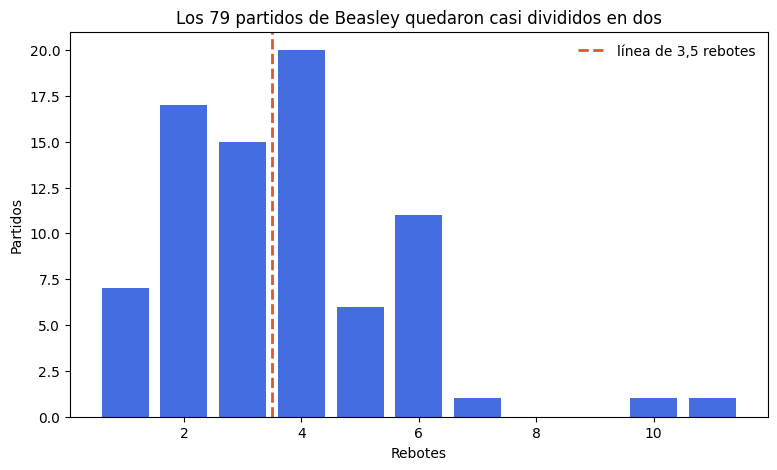

In [4]:
# cuento cuántas veces apareció cada total de rebotes
distribucion = datos['REB'].value_counts().sort_index().rename_axis('rebotes').reset_index(name='partidos')

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(distribucion['rebotes'], distribucion['partidos'], color='#446ddf')
ax.axvline(3.5, color='#d85a30', linewidth=2, linestyle='--', label='línea de 3,5 rebotes')
ax.set(title='Los 79 partidos de Beasley quedaron casi divididos en dos', xlabel='Rebotes', ylabel='Partidos')
ax.legend(frameon=False)
plt.show()

## 3. ¿Parecen extraordinarios los cuatro partidos?

In [5]:
# calculo la frecuencia empírica de resultados comparables
partidos['percentil_rebotes'] = partidos['REB'].apply(lambda x: (datos['REB'] <= x).mean())
partidos['percentil_puntos'] = partidos['PTS'].apply(lambda x: (datos['PTS'] <= x).mean())
partidos[['FECHA', 'rival', 'MIN', 'PTS', 'REB', 'percentil_puntos', 'percentil_rebotes']]

,FECHA,rival,MIN,PTS,REB,percentil_puntos,percentil_rebotes
0,2024-01-26,Cleveland Cavaliers,27,3,3,0.113924,0.493671
1,2024-02-27,Charlotte Hornets,26,6,4,0.265823,0.746835
2,2024-03-10,Los Angeles Clippers,39,17,4,0.810127,0.746835
3,2024-03-21,Brooklyn Nets,31,16,6,0.746835,0.962025


In [6]:
frecuencias = pd.Series({
    'menos_de_3_5_rebotes': (datos['REB'] <= 3).mean(),
    'mas_de_3_5_rebotes': (datos['REB'] >= 4).mean(),
    'menos_de_12_5_puntos': (datos['PTS'] <= 12).mean(),
    'menos_de_12_5_puntos_y_mas_de_3_5_rebotes': ((datos['PTS'] <= 12) & (datos['REB'] >= 4)).mean(),
    'seis_o_mas_rebotes': (datos['REB'] >= 6).mean(),
})
frecuencias

menos_de_3_5_rebotes                         0.493671
mas_de_3_5_rebotes                           0.506329
menos_de_12_5_puntos                         0.582278
menos_de_12_5_puntos_y_mas_de_3_5_rebotes    0.278481
seis_o_mas_rebotes                           0.177215
dtype: float64

## 4. Resultado y archivos reproducibles

Los cuatro registros de rebotes no son valores extremos dentro de la temporada. Tres y cuatro rebotes están en el centro de la distribución; seis rebotes o más sucedieron en 14 de los 79 encuentros. El partido de Charlotte combinó seis puntos con cuatro rebotes, una combinación que apareció, con esos umbrales, en 22 partidos.

La conclusión periodística es limitada pero clara: mirando solo el marcador individual no se puede reconocer de forma fiable un partido señalado por apuestas. La línea de 3,5 rebotes dividió la temporada 39 a 40, y una sola captura separó repetidamente ambos lados.

In [7]:
columnas_salida = ['FECHA', 'rival', 'objetivo', 'MIN', 'PTS', 'REB', 'percentil_puntos', 'percentil_rebotes']
partidos[columnas_salida].to_csv('resumen_partidos_investigados.csv', index=False)
distribucion.to_csv('distribucion_rebotes.csv', index=False)
print('Archivos creados: resumen_partidos_investigados.csv y distribucion_rebotes.csv')

Archivos creados: resumen_partidos_investigados.csv y distribucion_rebotes.csv
